# Practical Work 7 — Random Forest

## Dry Bean Dataset

Цель работы:
- Построить модель Decision Tree.
- Построить модель Random Forest.
- Настроить гиперпараметры Random Forest.
- Проанализировать важность признаков.
- Проверить влияние удаления наименее важных признаков.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.io import arff

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


In [49]:
DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "DryBeanDataset"
    / "Dry_Bean_Dataset.arff"
)

print("Путь к датасету:", DATA_PATH)
print("Файл найден:", DATA_PATH.exists())

Путь к датасету: c:\Users\user\Documents\Practical_1_EDA\Practical_7_Random_Forest\data\DryBeanDataset\Dry_Bean_Dataset.arff
Файл найден: True


In [50]:
from pathlib import Path

folder = Path.cwd().parent / "data" / "DryBeanDataset"

print("Папка существует:", folder.exists())

if folder.exists():
    for file in folder.iterdir():
        print(file.name)

Папка существует: True
Dry_Bean_Dataset.arff
Dry_Bean_Dataset_description.txt


In [51]:
from pathlib import Path

DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "DryBeanDataset"
    / "Dry_Bean_Dataset.arff"
)

print("Путь:", DATA_PATH)
print("Файл найден:", DATA_PATH.exists())

Путь: c:\Users\user\Documents\Practical_1_EDA\Practical_7_Random_Forest\data\DryBeanDataset\Dry_Bean_Dataset.arff
Файл найден: True


In [52]:
from scipy.io import arff
import pandas as pd

data, metadata = arff.loadarff(DATA_PATH)

df = pd.DataFrame(data)

for column in df.select_dtypes(include=["object"]).columns:
    df[column] = df[column].apply(
        lambda value: value.decode("utf-8")
        if isinstance(value, bytes)
        else value
    )

print("Данные успешно загружены!")
print("Размер датасета:", df.shape)

display(df.head())

Данные успешно загружены!
Размер датасета: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [53]:
print("Размер датасета:")
print(df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nИнформация о датасете:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())


Размер датасета:
(13611, 17)

Названия столбцов:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  float64
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  float64
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non

In [54]:
print("Количество объектов каждого класса:")
print(df["Class"].value_counts())

print("\nДоля каждого класса в процентах:")
print((df["Class"].value_counts(normalize=True) * 100).round(2))

Количество объектов каждого класса:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Доля каждого класса в процентах:
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64


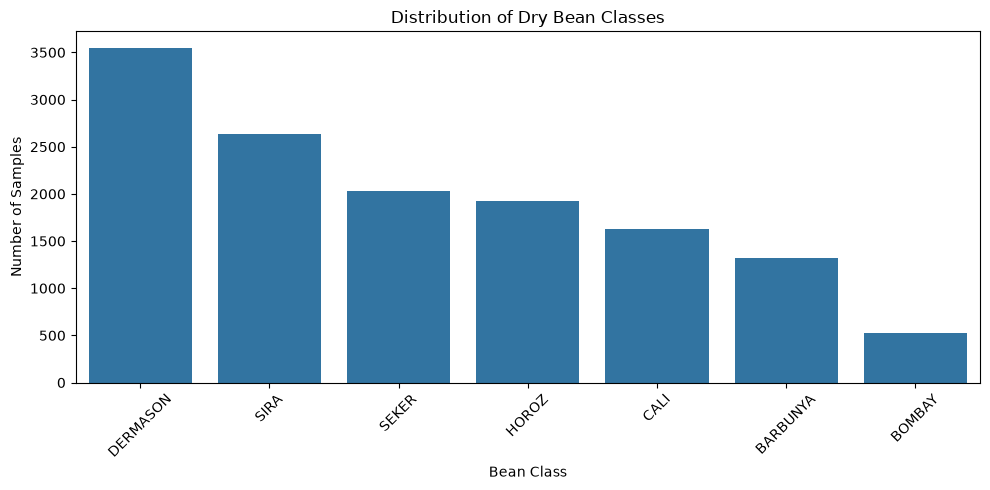

In [55]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Размер X:", X.shape)
print("Размер y:", y.shape)

print("\nПризнаки:")
print(X.columns.tolist())

print("\nЦелевая переменная:")
print(y.name)

Размер X: (13611, 16)
Размер y: (13611,)

Признаки:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Целевая переменная:
Class


In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print("\nКоличество объектов:")
print("Train:", len(X_train))
print("Test:", len(X_test))

Обучающая выборка: (10888, 16)
Тестовая выборка: (2723, 16)

Количество объектов:
Train: 10888
Test: 2723


In [58]:
decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train, y_train)

print("Модель Decision Tree обучена!")

Модель Decision Tree обучена!


In [59]:
y_pred_tree = decision_tree.predict(X_test)

tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree, average="macro")

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy: {tree_accuracy:.4f}")
print(f"Macro F1-score: {tree_f1:.4f}")

Decision Tree Results
---------------------
Accuracy: 0.8917
Macro F1-score: 0.9085


In [60]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

    BARBUNYA       0.89      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.92      0.92       326
    DERMASON       0.88      0.89      0.88       709
       HOROZ       0.94      0.92      0.93       386
       SEKER       0.91      0.94      0.92       406
        SIRA       0.83      0.79      0.81       527

    accuracy                           0.89      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.89      0.89      0.89      2723



In [61]:
rf_default = RandomForestClassifier(random_state=42)

rf_default.fit(X_train, y_train)

print("Модель Random Forest Default обучена!")
print("Количество деревьев:", rf_default.n_estimators)

Модель Random Forest Default обучена!
Количество деревьев: 100


In [62]:
y_pred_rf_default = rf_default.predict(X_test)

rf_default_accuracy = accuracy_score(y_test, y_pred_rf_default)
rf_default_f1 = f1_score(
    y_test,
    y_pred_rf_default,
    average="macro"
)

print("Random Forest Default Results")
print("-----------------------------")
print(f"Accuracy: {rf_default_accuracy:.4f}")
print(f"Macro F1-score: {rf_default_f1:.4f}")

Random Forest Default Results
-----------------------------
Accuracy: 0.9218
Macro F1-score: 0.9341


In [63]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest Default"],
    "Accuracy": [tree_accuracy, rf_default_accuracy],
    "Macro F1-score": [tree_f1, rf_default_f1]
})

display(comparison)

,Model,Accuracy,Macro F1-score
0,Decision Tree,0.891664,0.908493
1,Random Forest Default,0.921777,0.934114


In [64]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_leaf": [1, 2, 4]
}

print("Параметры для настройки:")
print(param_grid)

print("\nКоличество комбинаций:", 
      len(param_grid["n_estimators"]) *
      len(param_grid["max_depth"]) *
      len(param_grid["min_samples_leaf"]))

Параметры для настройки:
{'n_estimators': [100, 200], 'max_depth': [None, 20, 30], 'min_samples_leaf': [1, 2, 4]}

Количество комбинаций: 18


In [65]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Подбор параметров завершён!")

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Подбор параметров завершён!


In [66]:
print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший результат кросс-валидации:")
print(round(grid_search.best_score_, 4))

Лучшие параметры:
{'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}

Лучший результат кросс-валидации:
0.9352


In [67]:
rf_tuned = grid_search.best_estimator_

print("Настроенная модель создана!")
print("\nЛучшие параметры:")
print(rf_tuned.get_params())

Настроенная модель создана!

Лучшие параметры:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [68]:
y_pred_rf_tuned = rf_tuned.predict(X_test)

rf_tuned_accuracy = accuracy_score(y_test, y_pred_rf_tuned)

rf_tuned_f1 = f1_score(
    y_test,
    y_pred_rf_tuned,
    average="macro"
)

print("Random Forest Tuned Results")
print("---------------------------")
print(f"Accuracy: {rf_tuned_accuracy:.4f}")
print(f"Macro F1-score: {rf_tuned_f1:.4f}")

Random Forest Tuned Results
---------------------------
Accuracy: 0.9203
Macro F1-score: 0.9325


In [69]:
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest Default",
        "Random Forest Tuned"
    ],
    "Accuracy": [
        tree_accuracy,
        rf_default_accuracy,
        rf_tuned_accuracy
    ],
    "Macro F1-score": [
        tree_f1,
        rf_default_f1,
        rf_tuned_f1
    ]
})

display(comparison.round(4))

,Model,Accuracy,Macro F1-score
0,Decision Tree,0.8917,0.9085
1,Random Forest Default,0.9218,0.9341
2,Random Forest Tuned,0.9203,0.9325


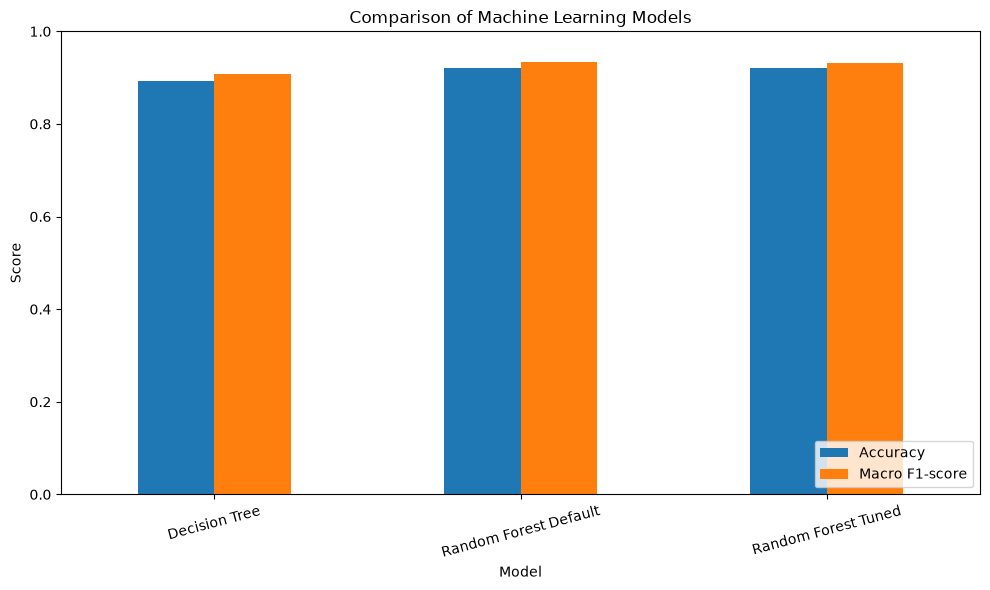

In [70]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [71]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_tuned.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
14,ShapeFactor3,0.1084
1,Perimeter,0.0896
11,Compactness,0.0866
12,ShapeFactor1,0.0830
3,MinorAxisLength,0.0816
2,MajorAxisLength,0.0808
6,ConvexArea,0.0738
0,Area,0.0618
5,Eccentricity,0.0616
4,AspectRation,0.0592


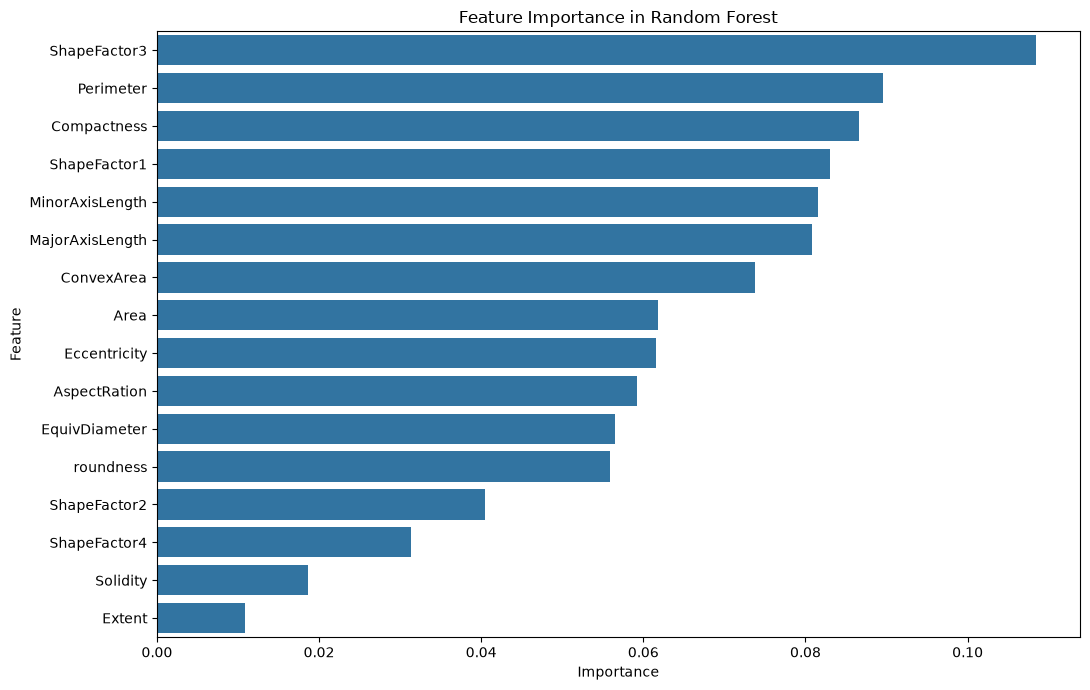

In [72]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [73]:
print("Топ-5 самых важных признаков:")
display(feature_importance.head(5))

print("\n5 наименее важных признаков:")
display(feature_importance.tail(5))

Топ-5 самых важных признаков:


,Feature,Importance
14,ShapeFactor3,0.108438
1,Perimeter,0.089606
11,Compactness,0.086575
12,ShapeFactor1,0.082985
3,MinorAxisLength,0.081564



5 наименее важных признаков:


,Feature,Importance
10,roundness,0.055913
13,ShapeFactor2,0.040433
15,ShapeFactor4,0.031279
9,Solidity,0.018667
8,Extent,0.010813


In [74]:
feature_sets = {
    "16 features": feature_importance["Feature"].head(16).tolist(),
    "12 features": feature_importance["Feature"].head(12).tolist(),
    "8 features": feature_importance["Feature"].head(8).tolist(),
    "4 features": feature_importance["Feature"].head(4).tolist()
}

for name, features in feature_sets.items():
    print(name, ":", len(features), "признаков")

16 features : 16 признаков
12 features : 12 признаков
8 features : 8 признаков
4 features : 4 признаков


In [75]:
feature_results = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        **grid_search.best_params_,
        random_state=42
    )

    model.fit(X_train[features], y_train)

    predictions = model.predict(X_test[features])

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    feature_results.append({
        "Feature Set": name,
        "Number of Features": len(features),
        "Accuracy": accuracy,
        "Macro F1-score": macro_f1
    })

feature_results_df = pd.DataFrame(feature_results)

display(feature_results_df.round(4))

,Feature Set,Number of Features,Accuracy,Macro F1-score
0,16 features,16,0.9218,0.9335
1,12 features,12,0.9045,0.9167
2,8 features,8,0.9071,0.9202
3,4 features,4,0.9049,0.9168


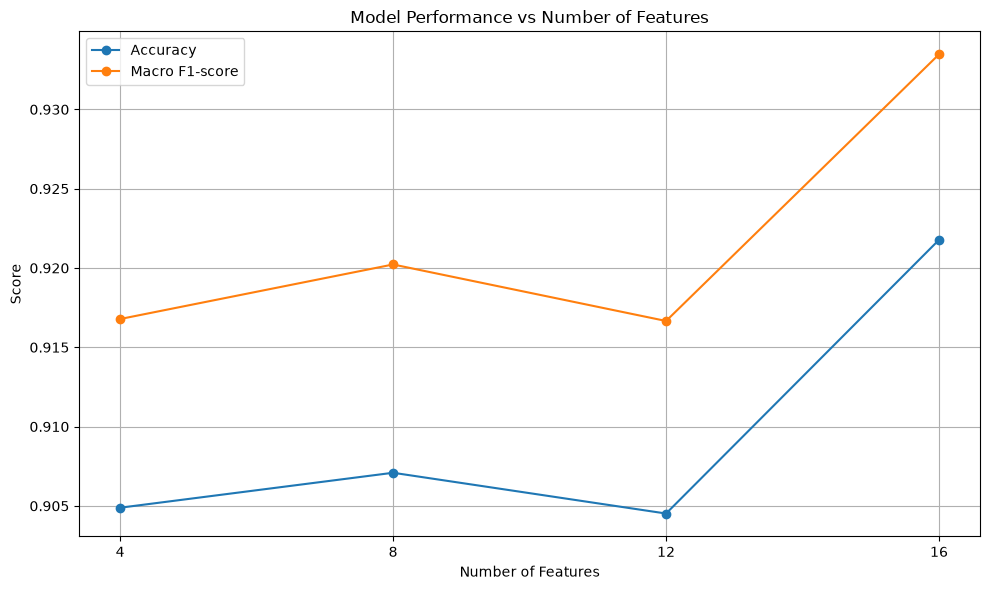

In [76]:
plt.figure(figsize=(10, 6))

plt.plot(
    feature_results_df["Number of Features"],
    feature_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    feature_results_df["Number of Features"],
    feature_results_df["Macro F1-score"],
    marker="o",
    label="Macro F1-score"
)

plt.title("Model Performance vs Number of Features")
plt.xlabel("Number of Features")
plt.ylabel("Score")
plt.xticks([4, 8, 12, 16])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [77]:
baseline_f1 = rf_tuned_f1

feature_results_df["F1 Difference"] = (
    feature_results_df["Macro F1-score"] - baseline_f1
)

display(feature_results_df.round(4))

,Feature Set,Number of Features,Accuracy,Macro F1-score,F1 Difference
0,16 features,16,0.9218,0.9335,0.0009
1,12 features,12,0.9045,0.9167,-0.0159
2,8 features,8,0.9071,0.9202,-0.0123
3,4 features,4,0.9049,0.9168,-0.0157


In [78]:
print("Classification Report — Random Forest Tuned")
print(classification_report(y_test, y_pred_rf_tuned))

Classification Report — Random Forest Tuned
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.93       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.86      0.86      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



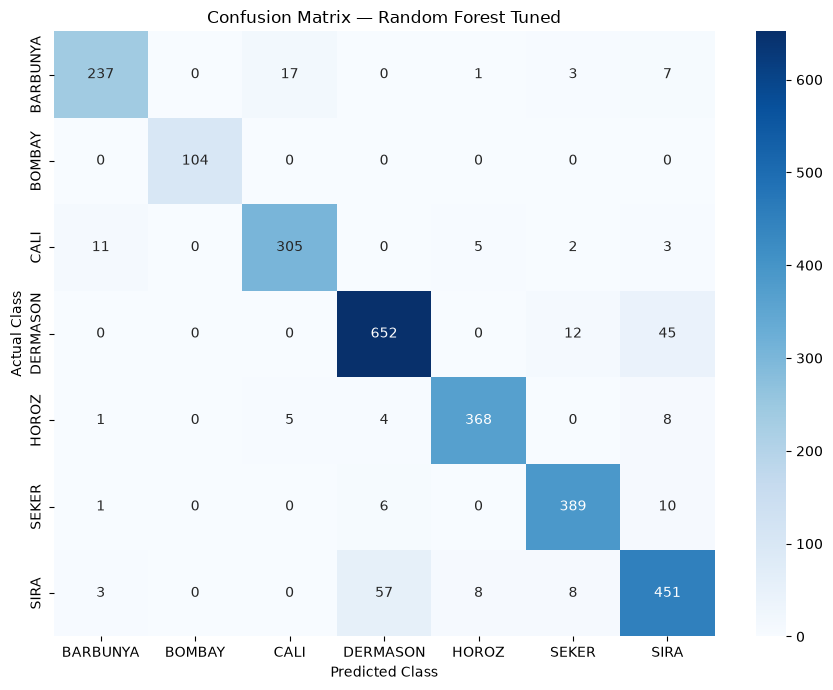

In [79]:
cm = confusion_matrix(y_test, y_pred_rf_tuned)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_tuned.classes_,
    yticklabels=rf_tuned.classes_
)

plt.title("Confusion Matrix — Random Forest Tuned")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [80]:
final_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest Default",
        "Random Forest Tuned"
    ],
    "Accuracy": [
        tree_accuracy,
        rf_default_accuracy,
        rf_tuned_accuracy
    ],
    "Macro F1-score": [
        tree_f1,
        rf_default_f1,
        rf_tuned_f1
    ]
})

final_results.to_csv(
    "../model_comparison.csv",
    index=False
)

print("Таблица сохранена: model_comparison.csv")
display(final_results.round(4))

Таблица сохранена: model_comparison.csv


,Model,Accuracy,Macro F1-score
0,Decision Tree,0.8917,0.9085
1,Random Forest Default,0.9218,0.9341
2,Random Forest Tuned,0.9203,0.9325


## Conclusion

In this practical work, Decision Tree and Random Forest classification models were developed using the Dry Bean Dataset.

The Random Forest model was trained with default parameters and then optimized using GridSearchCV and 3-fold cross-validation.

The models were compared using Accuracy and Macro F1-score on the same test dataset.

Feature importance was analyzed to identify the most informative characteristics of dry beans.

An additional experiment was conducted by reducing the number of features to 12, 8, and 4. The results were compared with the model using all 16 features.

The experiment helped evaluate whether less important features could be removed without significantly reducing classification quality.

The final conclusions are based on the obtained experimental results.